In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
import ast

# Load the data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)

# Create a scatter plot

c:\Users\dee\anaconda3\envs\data_analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
da= df[df['job_title_short'] == 'Data Analyst']

da_exploded = da.explode('job_skills')

In [3]:
da_exploded.groupby('job_skills'). agg(
    skills_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
).sort_values('skills_count', ascending=False).head(10)


,skills_count,median_salary
job_skills,,
sql,92428,92500.0
excel,66860,84479.0
python,57190,98500.0
tableau,46455,95000.0
power bi,39380,90000.0
r,29996,92527.5
sas,27998,90000.0
powerpoint,13822,85000.0
word,13562,80000.0


In [4]:
df_stat = da_exploded.groupby('job_skills').agg(
    skills_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
)

skills_stats = df_stat.sort_values('skills_count', ascending=False).head(10)


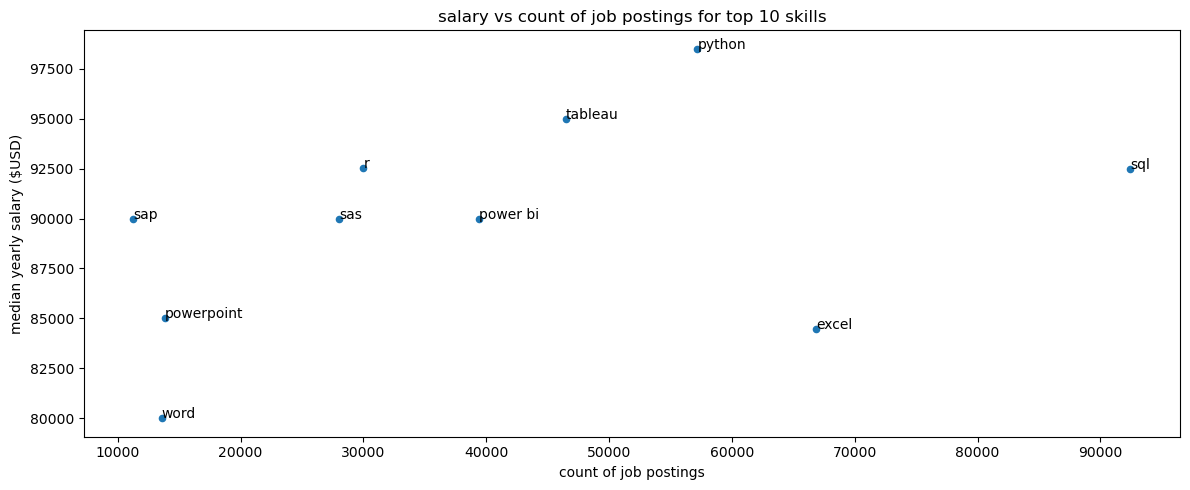

In [5]:
skills_stats.plot(kind = 'scatter', x = 'skills_count', y = 'median_salary', figsize = (12, 5))
plt.xlabel('count of job postings')
plt.ylabel('median yearly salary ($USD)')
plt.title('salary vs count of job postings for top 10 skills')

for i, txt in enumerate(skills_stats.index):
    plt.text(
        skills_stats['skills_count'].iloc[i],
        skills_stats['median_salary'].iloc[i],
        txt
    )
plt.tight_layout()
plt.show()

In [6]:
ds = df[df['job_title_short'] == 'Data Scientist']

ds_exploded = ds.explode('job_skills')

In [7]:
ds_stats = ds_exploded.groupby('job_skills').agg(
    skills_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
).sort_values('skills_count', ascending=False).head(15)

In [8]:
ds_stats

,skills_count,median_salary
job_skills,,
python,113711,130500.0
sql,78982,132500.0
r,59566,125000.0
sas,29534,119000.0
tableau,29445,125000.0
aws,26256,132500.0
spark,24286,135000.0
azure,21664,127500.0
tensorflow,19153,140000.0


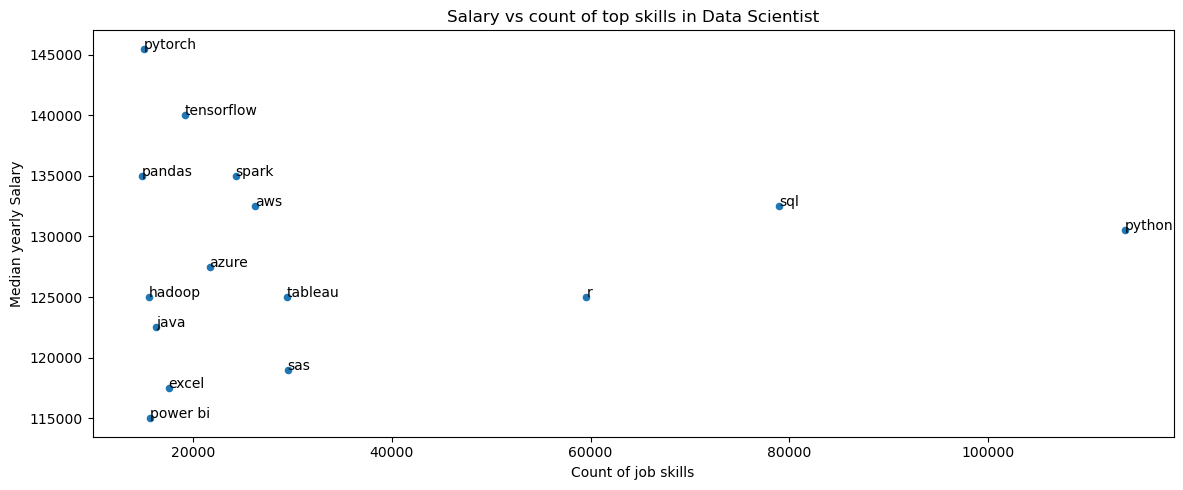

In [9]:
ds_stats.plot.scatter( x='skills_count', y='median_salary',figsize=(12,5))

plt.title('Salary vs count of top skills in Data Scientist')
plt.xlabel('Count of job skills')
plt.ylabel('Median yearly Salary')

for i, txt in enumerate (ds_stats.index):
    plt.text(
       ds_stats['skills_count'].iloc[i],
       ds_stats['median_salary'].iloc[i],
       txt
    )
    
plt.tight_layout()
plt.show()